In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [4]:
if "HeartDisease" in df.columns:
    X = df.drop("HeartDisease", axis=1).copy()
else:
    X = df.copy()

print("Features Used for Clustering:")
print(X.columns.tolist())

Features Used for Clustering:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [6]:
categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['Gender']

Numerical Columns:
['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [7]:
X = X.replace([np.inf, -np.inf], np.nan)

for column in numerical_columns:
    X[column] = X[column].fillna(X[column].median())

for column in categorical_columns:
    mode_values = X[column].mode()
    fill_value = (
        mode_values.iloc[0]
        if not mode_values.empty
        else "Unknown"
    )
    X[column] = X[column].fillna(fill_value)

print("Missing Values After Cleaning:")
print(X.isnull().sum())

Missing Values After Cleaning:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [9]:
transformers = []

if numerical_columns:
    transformers.append(
        ("numerical", StandardScaler(), numerical_columns)
    )

if categorical_columns:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=0
)

X_processed = preprocessor.fit_transform(X)

print("Processed Dataset Shape:", X_processed.shape)

Processed Dataset Shape: (200, 6)


In [10]:
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_processed)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_processed, labels)
    )

evaluation_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

evaluation_df.round(4)

,K,Inertia,Silhouette Score
0,2,614.0348,0.2787
1,3,473.3372,0.2836
2,4,357.5476,0.3410
3,5,307.4516,0.3447
4,6,257.4263,0.3432
5,7,236.5466,0.3300
6,8,213.9907,0.3405
7,9,196.8690,0.3420
8,10,179.2245,0.3395


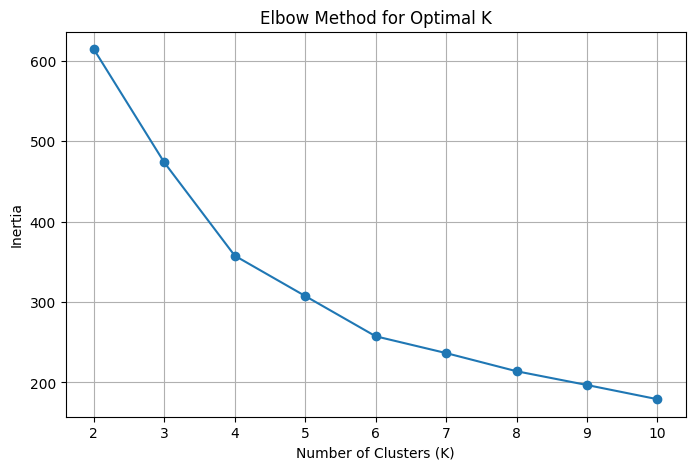

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

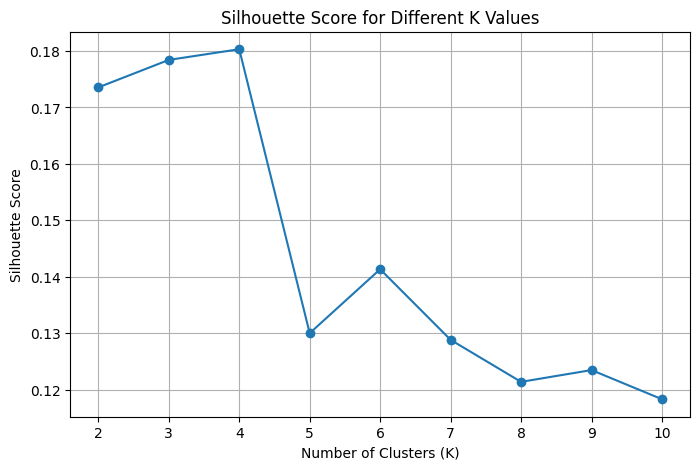

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [12]:
k = 3

kmeans_model = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=10,
    random_state=42
)

cluster_labels = kmeans_model.fit_predict(X_processed)

clustered_df = df.copy()
clustered_df["Cluster"] = cluster_labels

print("K-MEANS CLUSTERING")
print("------------------")
print("Number of Clusters:", k)
print("Inertia:", round(kmeans_model.inertia_, 4))

print(
    "Silhouette Score:",
    round(silhouette_score(X_processed, cluster_labels), 4)
)

K-MEANS CLUSTERING
------------------
Number of Clusters: 3
Inertia: 473.3372
Silhouette Score: 0.2836


In [13]:
print("First 10 Cluster Assignments:")

print(
    clustered_df[
        clustered_df.columns.tolist()
    ].head(10)
)

First 10 Cluster Assignments:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        2  
1        2  
2        2  
3        2  
4        2  
5        2  
6        2  
7        2  
8        1  
9        2  


In [14]:
cluster_counts = (
    clustered_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Records in Each Cluster:")
print(cluster_counts)

Records in Each Cluster:
Cluster
0    81
1    62
2    57
Name: count, dtype: int64


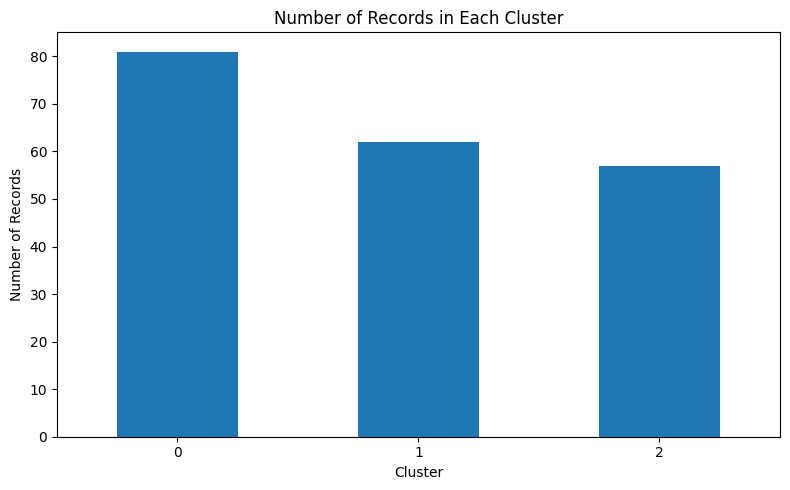

In [15]:
cluster_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of Records in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
if numerical_columns:
    cluster_profiles = clustered_df.groupby("Cluster")[
        numerical_columns
    ].mean()

    print("Average Numerical Values per Cluster:")
    display(cluster_profiles.round(2))

Average Numerical Values per Cluster:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,159.22,35.14,85.49,52.17
1,73.11,54.98,49.42,40.34
2,46.84,26.58,37.25,58.12


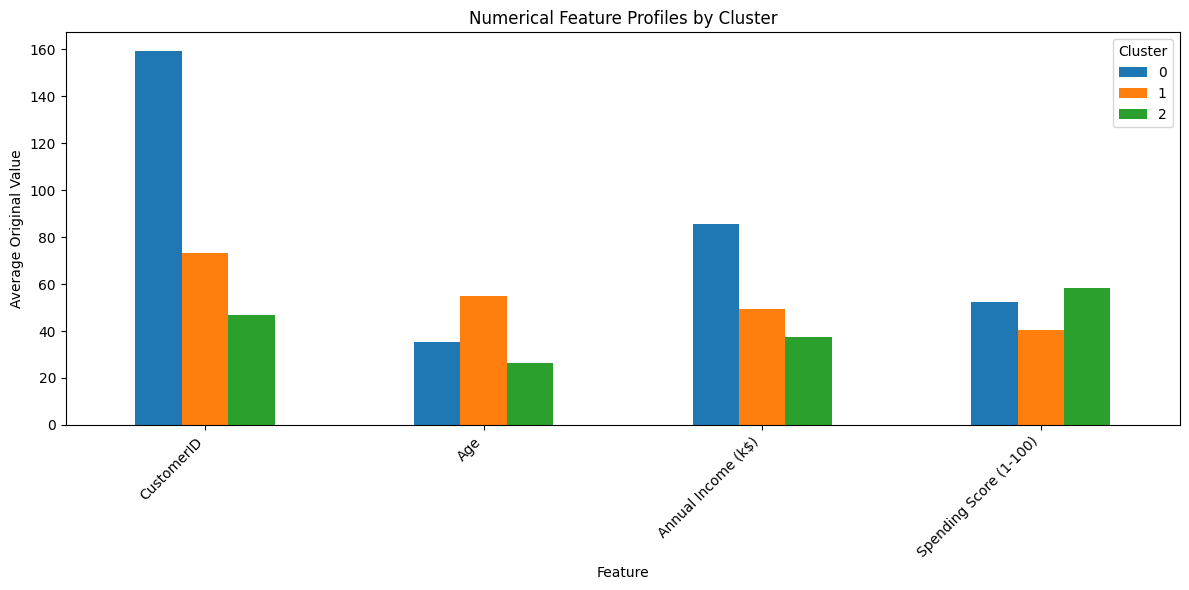

In [17]:
if numerical_columns:
    cluster_profiles.T.plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title("Numerical Feature Profiles by Cluster")
    plt.xlabel("Feature")
    plt.ylabel("Average Original Value")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Cluster")
    plt.tight_layout()
    plt.show()

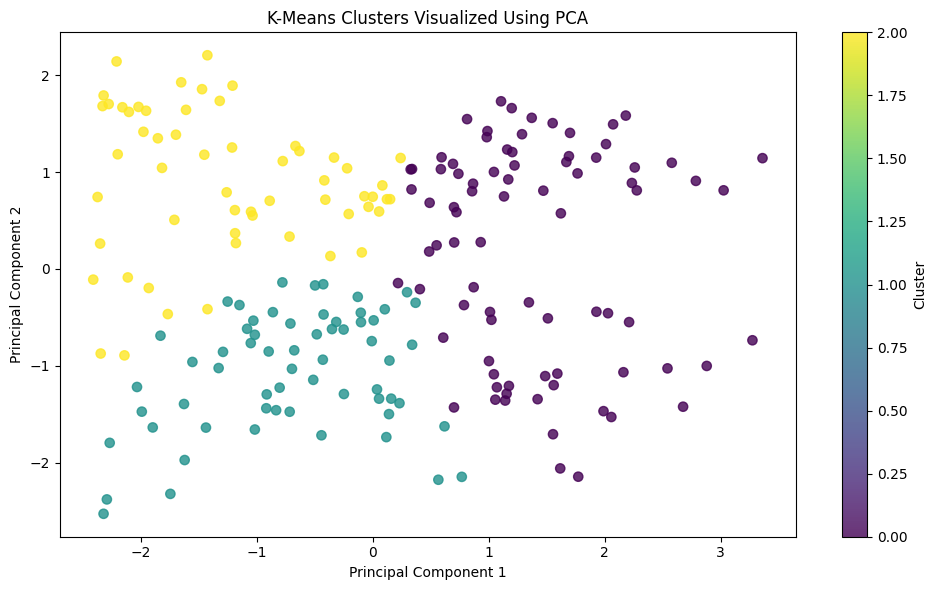

Variance represented by two PCA components: 73.7 %


In [18]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_processed)

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=45,
    alpha=0.8
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance represented by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [19]:
output_file = "heart_clustered.csv"

clustered_df.to_csv(output_file, index=False)

print("Clustered Dataset Saved Successfully!")
print("Output File:", output_file)

Clustered Dataset Saved Successfully!
Output File: heart_clustered.csv


In [21]:
summary = (
    clustered_df.groupby("Cluster")
    .size()
    .reset_index(name="Number of Records")
)

summary["Percentage"] = (
    summary["Number of Records"]
    / len(clustered_df)
    * 100
).round(2)

print("FINAL CLUSTER SUMMARY")
print("=====================")

display(summary)

print("K-Means clustering completed successfully!")

FINAL CLUSTER SUMMARY


,Cluster,Number of Records,Percentage
0,0,81,40.5
1,1,62,31.0
2,2,57,28.5


K-Means clustering completed successfully!
